In [ ]:
# install libraries

%pip install pandas matplotlib

In [2]:
# Open the clean places file and call it places
import pandas as pd
import matplotlib.pyplot as plt

places = pd.read_csv("../data/processed/london_places.csv")
print(places.shape)
places.head()

Matplotlib is building the font cache; this may take a moment.


(17751, 6)


,osm_id,code,fclass,name,lat,lon
0,451152,2304,pub,King of Prussia,51.600840,-0.194608
1,451153,2301,restaurant,Central Restaurant,51.602031,-0.193503
2,451154,2304,pub,The Catcher in the Rye,51.599579,-0.196028
3,451271,2304,pub,The Tally Ho,51.614104,-0.176556
4,12242503,2304,pub,Railway Bell,51.592016,0.027962


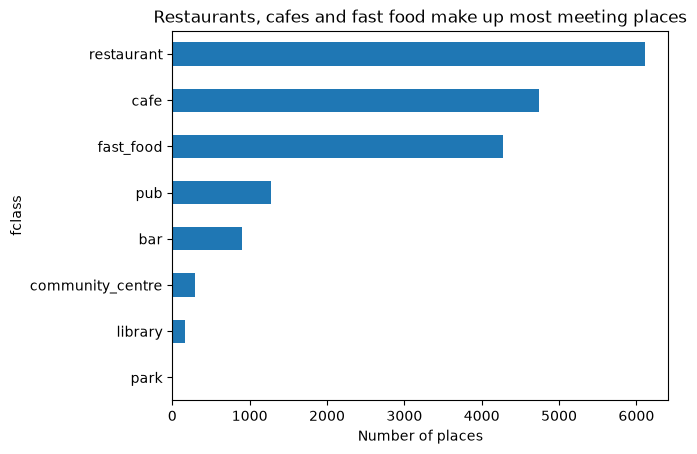

In [3]:
# how many of each type of place by using bar charts

counts = places["fclass"].value_counts(ascending=True)
counts.plot(kind="barh", title="Restaurants, cafes and fast food make up most meeting places")
plt.xlabel("Number of places")
plt.show()

As we can see...

In [ ]:
# straight line distance (km) from charing cross to chosen latitude and longitude
places["km_from_centre"] = (
    ((places["lat"] - 51.5073) * 111) ** 2
    + ((places["lon"] + 0.1276) * 69) ** 2
) ** 0.5

places["km_from_centre"].describe()

count    17751.000000
mean         8.323590
std          5.772231
min          0.052853
25%          3.537517
50%          7.147088
75%         12.373445
max         28.002049
Name: km_from_centre, dtype: float64

fclass
bar                  4.0
restaurant           6.0
cafe                 7.1
pub                  7.9
community_centre     8.7
fast_food            9.3
library              9.8
park                16.3
Name: km_from_centre, dtype: float64


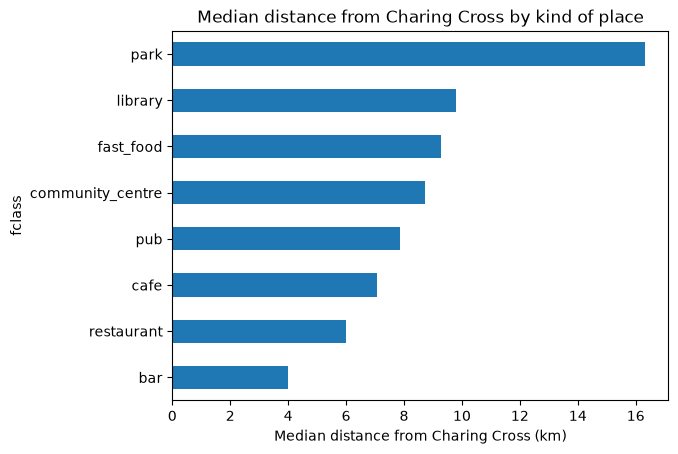

In [ ]:
# median straight line distance (km) from charing cross for each class using "km_from_centre"
by_type = places.groupby("fclass")["km_from_centre"].median().sort_values()
print(by_type.round(1))

by_type.plot(kind="barh", title="Median distance from Charing Cross by kind of place")
plt.xlabel("Median distance from Charing Cross (km)")
plt.show()

as we can see...

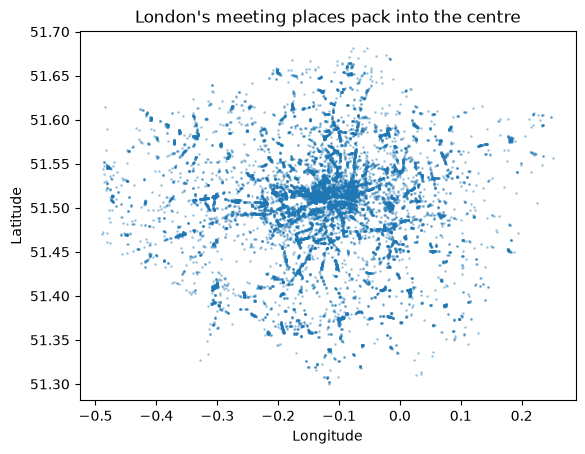

In [ ]:
# map every place to visually see the spread of places across london
places.plot(kind="scatter", x="lon", y="lat", s=1, alpha=0.3,
            title="London's meeting places pack into the centre")
plt.xlabel("Longitude")
plt.ylabel("Latitude")
plt.show()

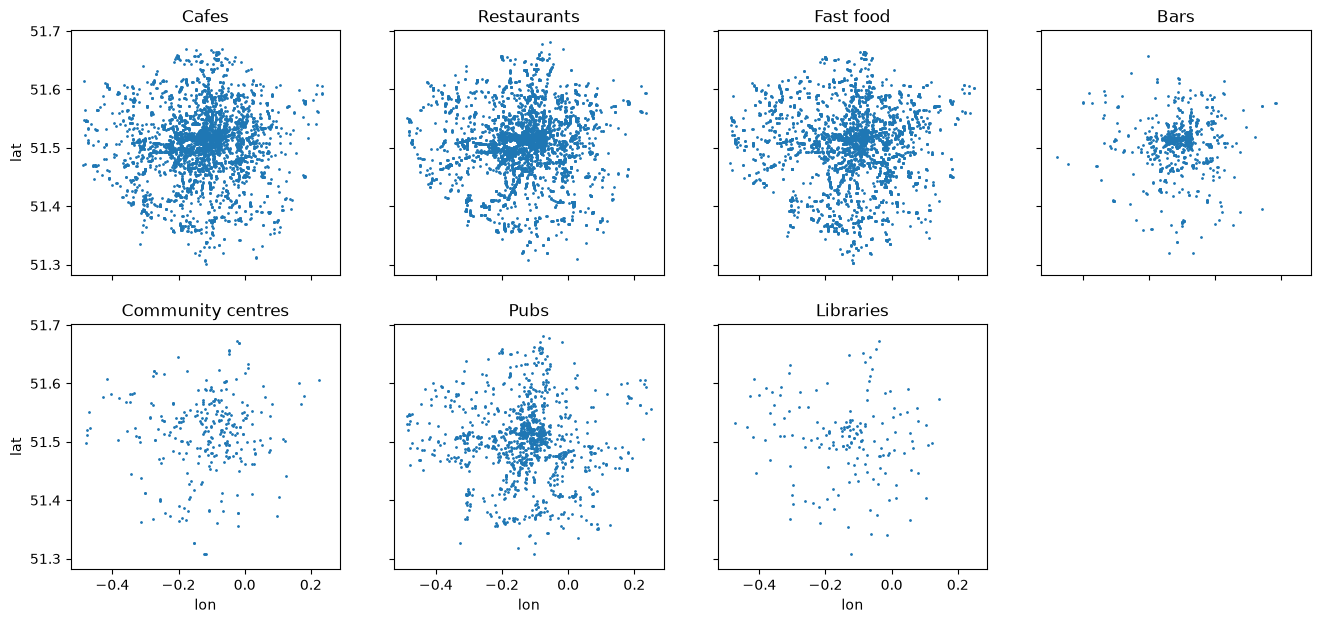

In [19]:
# one map per type of place and plotted side by side
fig, axes = plt.subplots(2, 4, figsize=(16, 7), sharex=True, sharey=True)
axes = axes.flatten()   # turn the 2x4 grid into one array from 0 to 7

places[places["fclass"] == "cafe"].plot(kind="scatter", x="lon", y="lat", s=1, ax=axes[0], title="Cafes")
places[places["fclass"] == "restaurant"].plot(kind="scatter", x="lon", y="lat", s=1, ax=axes[1], title="Restaurants")
places[places["fclass"] == "fast_food"].plot(kind="scatter", x="lon", y="lat", s=1, ax=axes[2], title="Fast food")
places[places["fclass"] == "bar"].plot(kind="scatter", x="lon", y="lat", s=1, ax=axes[3], title="Bars")
places[places["fclass"] == "community_centre"].plot(kind="scatter", x="lon", y="lat", s=1, ax=axes[4], title="Community centres")
places[places["fclass"] == "pub"].plot(kind="scatter", x="lon", y="lat", s=1, ax=axes[5], title="Pubs")
places[places["fclass"] == "library"].plot(kind="scatter", x="lon", y="lat", s=1, ax=axes[6], title="Libraries")
axes[7].axis("off")   


plt.show()

In [10]:
# Work out the outlier fences for distance from the centre
q1 = places["km_from_centre"].quantile(0.25)
q3 = places["km_from_centre"].quantile(0.75)
width = q3 - q1
lower = q1 - 1.5 * width
upper = q3 + 1.5 * width

print("Box:", round(q1, 1), "to", round(q3, 1))
print("Flag below", round(lower, 1), "or above", round(upper, 1))

Box: 3.5 to 12.4
Flag below -9.7 or above 25.6


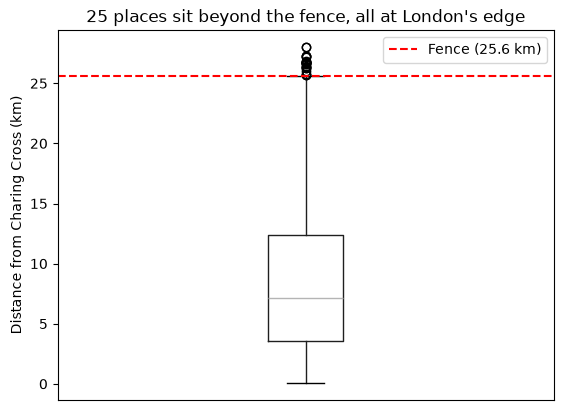

In [16]:
# Box plot of distance from the centre: dots are the outliers beyond the fence
places.boxplot(column="km_from_centre", grid=False)
plt.axhline(upper, color="red", linestyle="--", label=f"Fence ({upper:.1f} km)")
plt.title("25 places sit beyond the fence, all at London's edge")
plt.ylabel("Distance from Charing Cross (km)")
plt.xticks([])
plt.legend()
plt.show()